# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [10]:
%%writefile heap.py
import math
import matplotlib.pyplot as plt
import networkx as nx

class Heap:
    def __init__(self):
        self.arreglo = [float("-inf")]

    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        i = len(self.arreglo) - 1

        while self.arreglo[i] < self.arreglo[i // 2]:
            self.arreglo[i], self.arreglo[i // 2] = (
                self.arreglo[i // 2],
                self.arreglo[i],
            )
            i = i // 2

        if imagen:
            self._mostrar_imagen()

    def remove_smallest(self, imagen=False):
        if len(self.arreglo) <= 1:
            return None

        if len(self.arreglo) == 2:
            val = self.arreglo.pop()
            if imagen:
                self._mostrar_imagen()
            return val

        minimo = self.arreglo[1]
        self.arreglo[1] = self.arreglo.pop()

        i = 1
        n = len(self.arreglo)

        while True:
            hijo_izq = 2 * i
            hijo_der = 2 * i + 1
            menor = i

            if hijo_izq < n and self.arreglo[hijo_izq] < self.arreglo[menor]:
                menor = hijo_izq

            if hijo_der < n and self.arreglo[hijo_der] < self.arreglo[menor]:
                menor = hijo_der

            if menor == i:
                break

            self.arreglo[i], self.arreglo[menor] = (
                self.arreglo[menor],
                self.arreglo[i],
            )
            i = menor

        if imagen:
            self._mostrar_imagen()

        return minimo

    def build_heap(self, lista, imagen=False):
        # 1. Copiar los elementos respetando self.arreglo[0] = -inf
        self.arreglo = [float("-inf")] + list(lista)
        
        # 2. Algoritmo de Floyd: hundir desde el último nodo interno hasta la raíz (1)
        n = len(self.arreglo)
        for i in range((n - 1) // 2, 0, -1):
            curr = i
            while True:
                hijo_izq = 2 * curr
                hijo_der = 2 * curr + 1
                menor = curr

                if hijo_izq < n and self.arreglo[hijo_izq] < self.arreglo[menor]:
                    menor = hijo_izq

                if hijo_der < n and self.arreglo[hijo_der] < self.arreglo[menor]:
                    menor = hijo_der

                if menor == curr:
                    break

                self.arreglo[curr], self.arreglo[menor] = (
                    self.arreglo[menor],
                    self.arreglo[curr],
                )
                curr = menor

        if imagen:
            self._mostrar_imagen()

    def _mostrar_imagen(self):
        n = len(self.arreglo) - 1
        if n <= 0:
            return

        G = nx.Graph()
        pos = {}

        for i in range(1, n + 1):
            G.add_node(i)
            if i > 1:
                G.add_edge(i // 2, i)

        profundidad_max = math.floor(math.log2(n)) if n > 0 else 0

        for i in range(1, n + 1):
            nivel = math.floor(math.log2(i))
            posicion_en_nivel = i - (2 ** nivel)
            nodos_en_nivel = 2 ** nivel

            ancho_nivel = 2 ** (profundidad_max - nivel + 1)
            x = (posicion_en_nivel + 0.5 - (nodos_en_nivel / 2)) * ancho_nivel
            y = -nivel
            pos[i] = (x, y)

        fig, ax = plt.subplots(figsize=(8, 5))
        labels = {i: str(self.arreglo[i]) for i in range(1, n + 1)}

        nx.draw_networkx_nodes(G, pos, node_color="#ADD8E6", node_size=1200, edgecolors="black", ax=ax)
        nx.draw_networkx_edges(G, pos, width=1.5, edge_color="black", ax=ax)
        nx.draw_networkx_labels(G, pos, labels=labels, font_size=11, font_weight="bold", ax=ax)

        ax.axis("off")
        plt.tight_layout()
        plt.show()

Overwriting heap.py


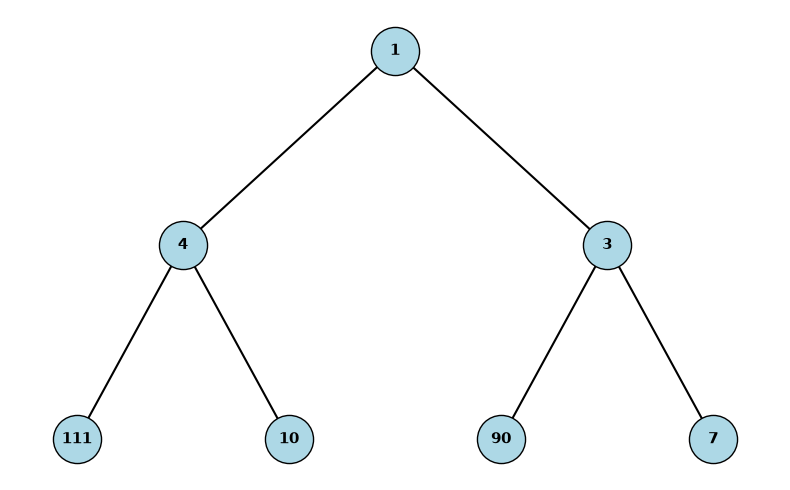

In [34]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(90)
H.insert(111)
H.insert(3)
H.insert(1)
H.insert(7, imagen=True)

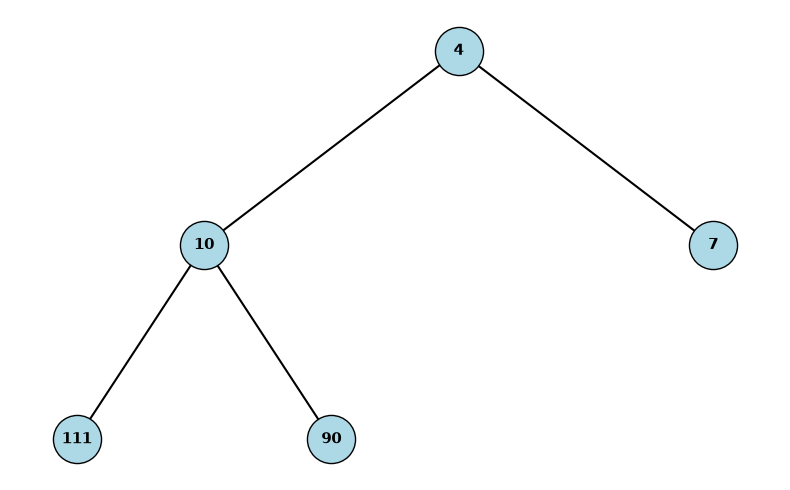

3

In [36]:
# Prueba de extracción
H.remove_smallest(imagen=True)



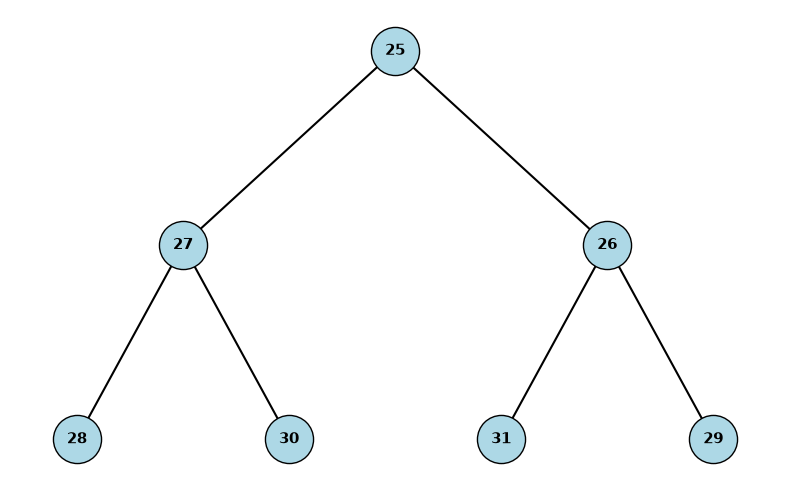

In [15]:
# Prueba de build_heap idéntico a Galles CS USFCA
H.build_heap([31, 30, 29, 28, 27, 26, 25], imagen=True)

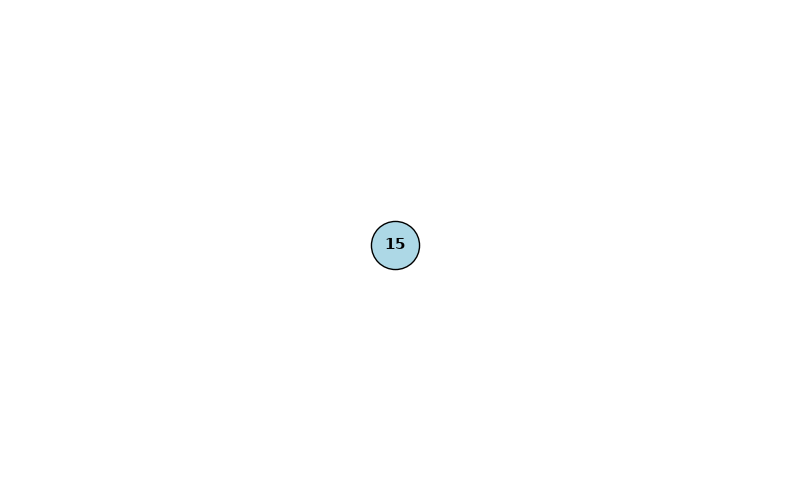

1 [-inf, 15]


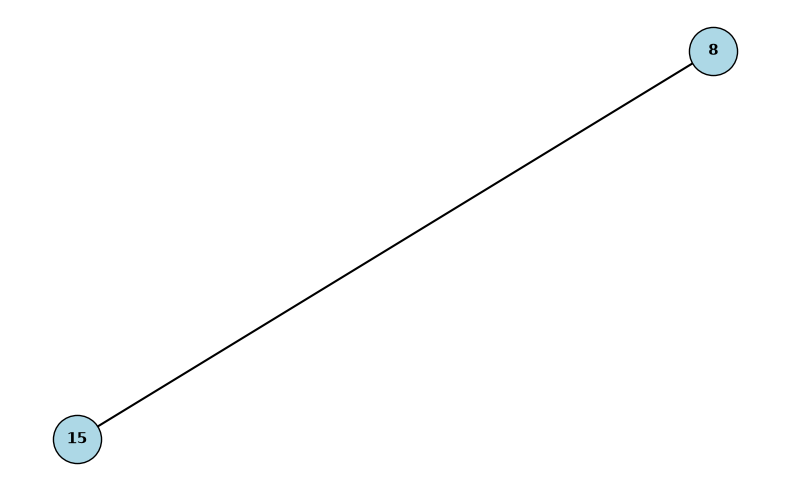

2 [-inf, 8, 15]


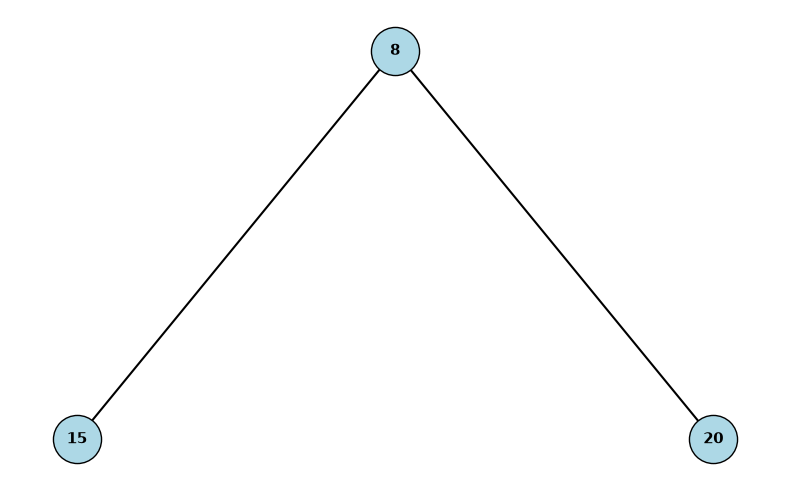

3 [-inf, 8, 15, 20]


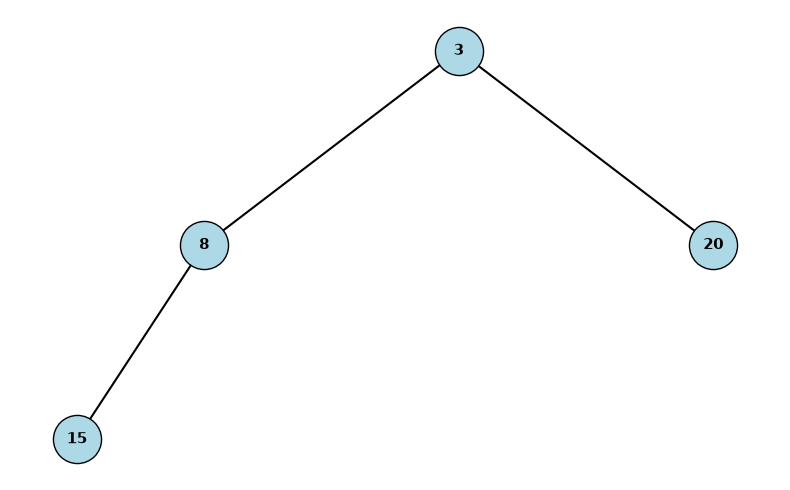

4 [-inf, 3, 8, 20, 15]


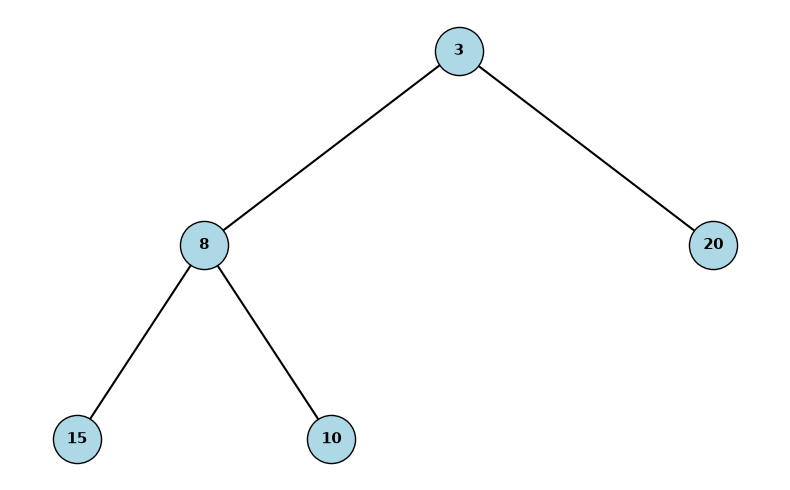

5 [-inf, 3, 8, 20, 15, 10]


In [1]:
import os
import importlib
import heap
importlib.reload(heap)
from heap import Heap

os.makedirs("fotos", exist_ok=True)     # crea la carpeta fotos si no existe

valores = [15, 8, 20, 3, 10]            # NO cambie esta lista

H = Heap()
for i, v in enumerate(valores, start=1):
    H.insert(v, imagen=True)
    # guarde aquí la imagen de esta inserción en f"fotos/insert_{i}.png"
    print(i, H.arreglo)